Visualize ERPs and replicate plots of original paper

In [1]:
import os
import sys
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

sys.path.append('../..')
from data.data_configs import *
from data.data_loader import DataLoader

2025-12-18 09:22:01.192661: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


In [2]:
ch_sel = ['Fz', 'Cz', 'Pz', 'Oz']

X, y, time_axis = DataLoader().load_labeled_eeg_data(SUBJECTS[0:27], ch_sel)

In [3]:
X.shape

(94090, 4, 500)

In [4]:
y.shape

(94090,)

In [5]:
def compute_erp_by_mask(X, y, positive_value=1):
    
    y_flat = np.squeeze(y)
    if y_flat.dtype == bool:
        mask_true = y_flat
    else:
        mask_true = (y_flat == positive_value)
    mask_true = np.squeeze(mask_true)
    
    # Ensure mask is 1D boolean aligned with trials
    if getattr(mask_true, "ndim", 1) > 1:
        mask_true = np.squeeze(mask_true)
    mask_true = mask_true.astype(bool)
    
    n_total = int(X.shape[0])
    n_true = int(np.sum(mask_true))
    mask_false = ~mask_true
    n_false = int(np.sum(mask_false))
    
    # Select trials
    X_true = X[mask_true]
    X_false = X[mask_false]
    
    # Average across trials axis (axis 0)
    erp_true = X_true.mean(axis=0)
    erp_false = X_false.mean(axis=0)
    
    # If single-channel, squeeze channel dimension
    if erp_true is not None and erp_true.ndim == 2 and erp_true.shape[0] == 1:
        erp_true = erp_true[0]
    if erp_false is not None and erp_false.ndim == 2 and erp_false.shape[0] == 1:
        erp_false = erp_false[0]
    
    print(f"Selected {n_true}/{n_total} True trials, {n_false}/{n_total} False trials")
    return erp_true, erp_false

In [ ]:
# Compute ERPs for True and False masks
erp_true, erp_false = compute_erp_by_mask(X, y)
erp_true.shape
erp_false.shape

Selected 38347/94090 True trials, 55743/94090 False trials


((4, 500), (4, 500))

In [7]:
def plot_erp(ch_true, ch_false):
    # Convert to microvolts for visibility
    erp_true_uv = ch_true * 1e6
    erp_false_uv = ch_false * 1e6

    plt.figure(figsize=(10, 4))
    plt.plot(time_axis * 1000, erp_true_uv, label="True mask")
    plt.plot(time_axis * 1000, erp_false_uv, label="False mask")
    plt.xlabel("Time (ms)")
    plt.ylabel("ERP (µV)")
    plt.title("Average ERP across True vs False trials")
    plt.grid(True)
    plt.legend()
    plt.tight_layout()
    plt.show()

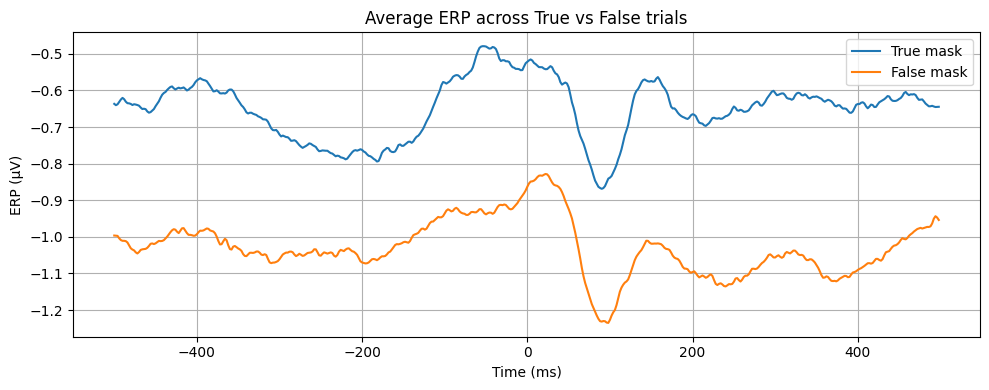

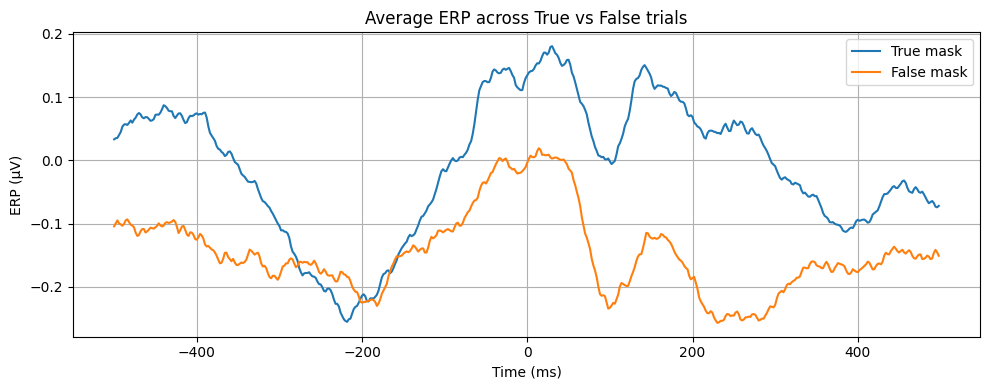

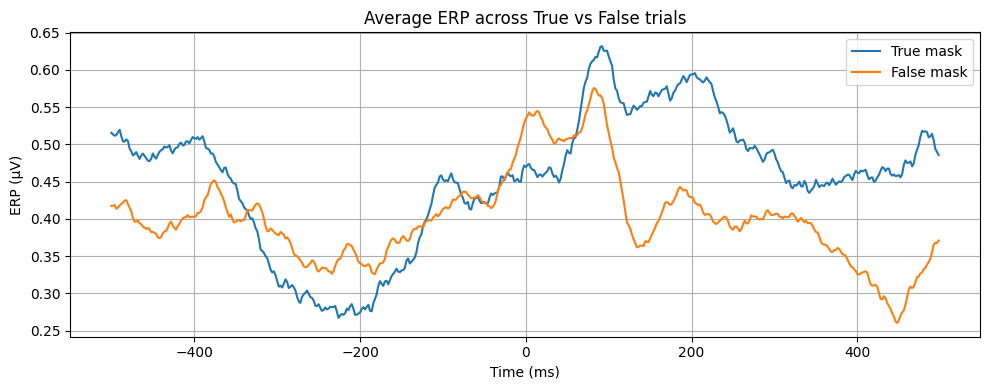

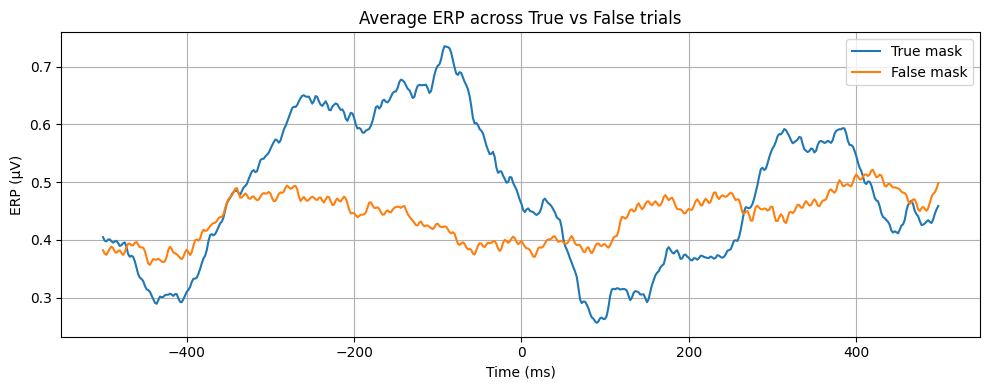

In [8]:
for channel in ch_sel:
    ch_true = erp_true[ch_sel.index(channel), :]
    ch_false = erp_false[ch_sel.index(channel), :]
    plot_erp(ch_true, ch_false)